Brayden Yow  
10/23/26    
Block 2

**Block 2 Checkpoint — Engine Demo**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from body import Body
from forces import UniformGravity, NewtonGravity, ElasticCollision, BoxBoundary
from integrators import EulerCromer, VelocityVerlet
from world import World

In [2]:

# 1. Initialize Engine Components
integrator = VelocityVerlet()
world = World(integrator)

# 2. Add 4 Interacting Bodies inside the box coordinates
world.add_body(Body(mass=1.2, position=[-3.0, 4.0], velocity=[4.5, -2.0], name="Ball_A"))
world.add_body(Body(mass=1.0, position=[3.0, 4.0], velocity=[-4.5, -2.0], name="Ball_B"))
world.add_body(Body(mass=1.5, position=[-1.0, 1.0], velocity=[2.0, 3.0], name="Ball_C"))
world.add_body(Body(mass=0.8, position=[1.0, -1.0], velocity=[-3.0, 5.0], name="Ball_D"))

# 3. Add the forces (Gravity + Ball-to-Ball Collisions + Wall Boundaries)
world.add_force(UniformGravity(g=9.81))
world.add_force(ElasticCollision(radius=0.4, restitution=1.0))
world.add_force(BoxBoundary(x_min=-5.0, x_max=5.0, y_min=-3.0, y_max=7.0, radius=0.4, restitution=1.0))

# 4. Run the simulation
dt = 0.01
total_steps = 100
for _ in range(total_steps):
    world.step(dt)


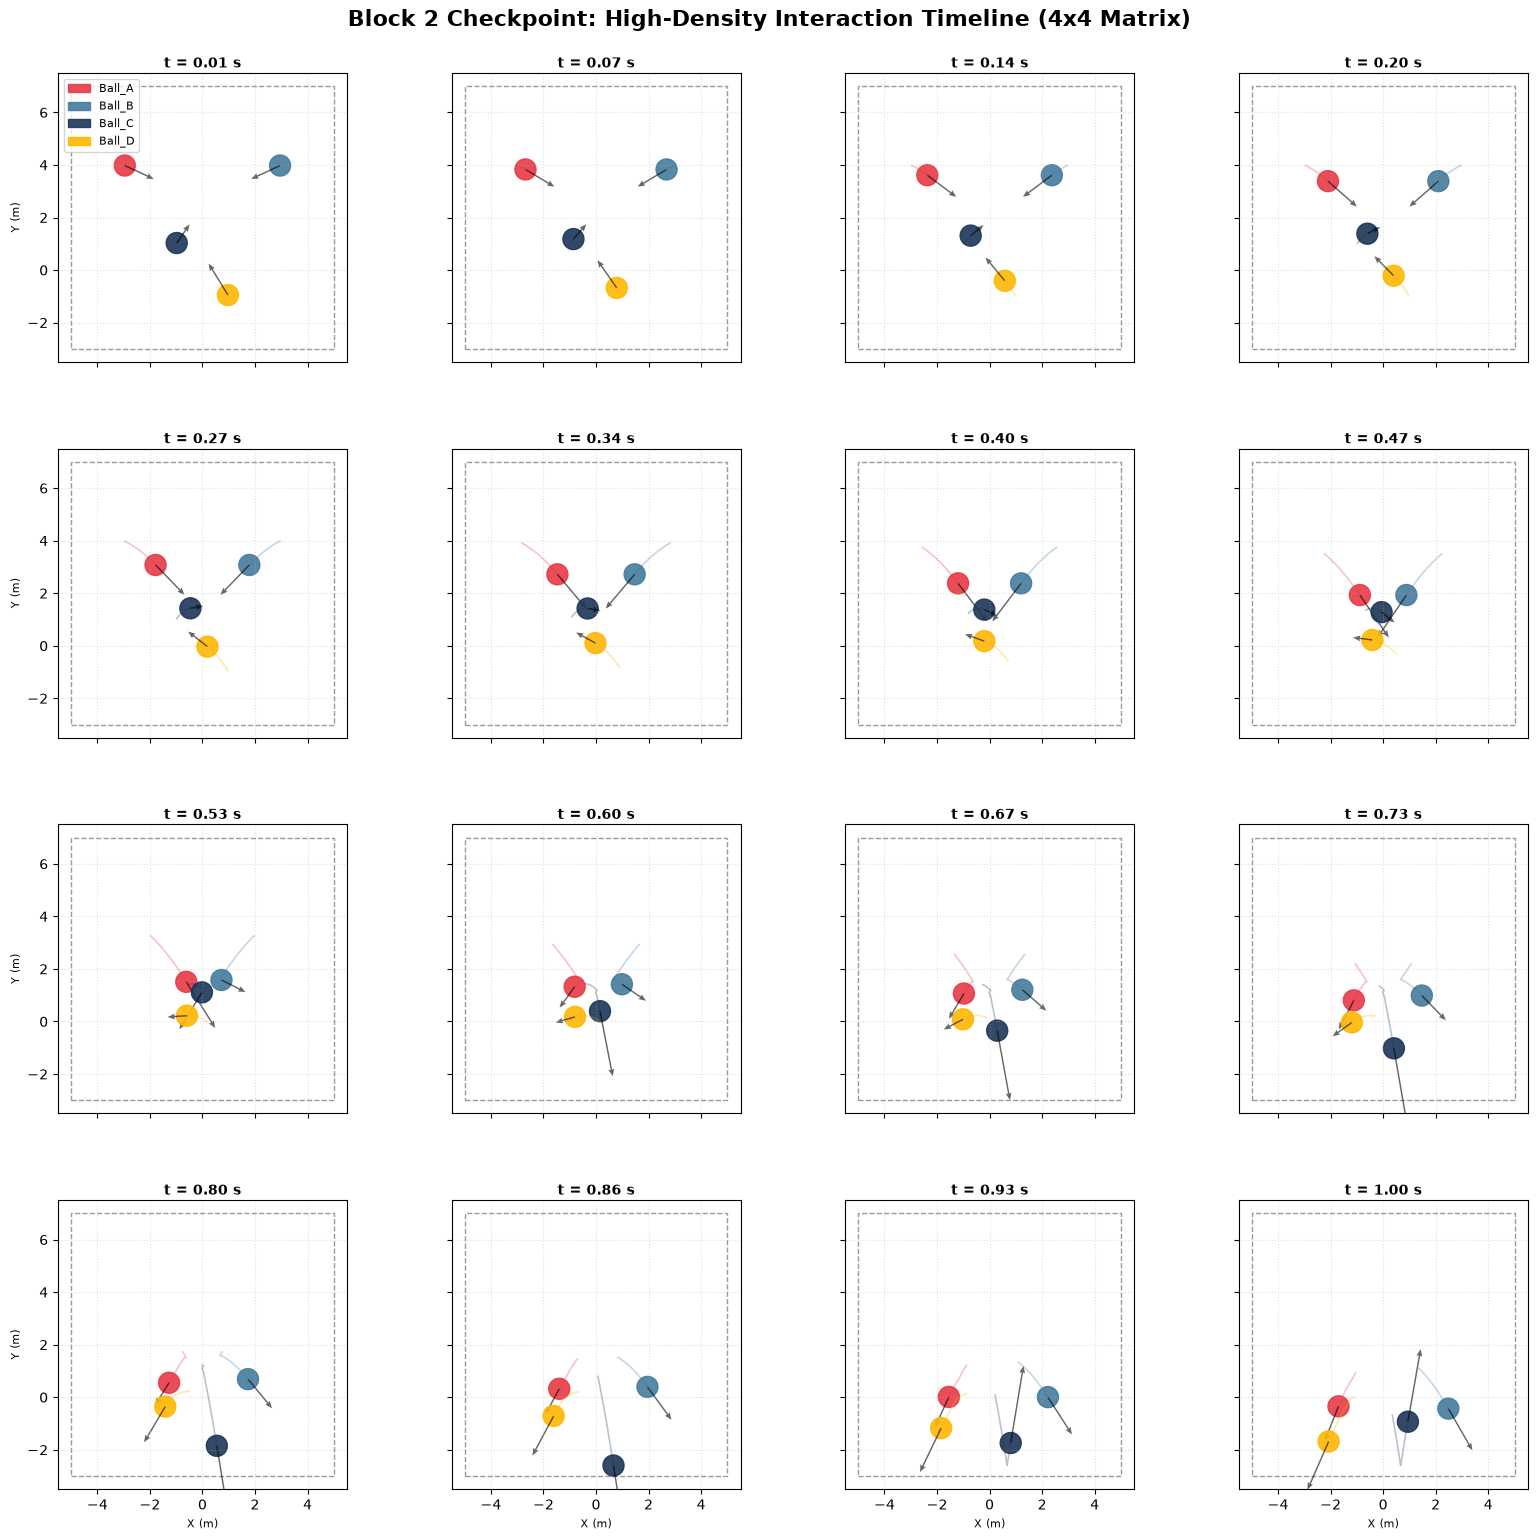

In [3]:
time_hist = world.history["time"]
body_names = list(world.history["bodies"].keys())

# Generate 16 evenly spaced indices over the 300-step timeline
snapshot_indices = np.linspace(0, total_steps - 1, 16, dtype=int)
radius = 0.4

colors = {"Ball_A": "#E63946", "Ball_B": "#457B9D", "Ball_C": "#1D3557", "Ball_D": "#FFB703"}

# Create a 4x4 matrix of subplots
fig, axes = plt.subplots(4, 4, figsize=(16, 16), sharex=True, sharey=True)
axes = axes.flatten()

for plot_idx, step_idx in enumerate(snapshot_indices):
    ax = axes[plot_idx]
    current_time = time_hist[step_idx]
    
    for name in body_names:
        pos_history = np.array(world.history["bodies"][name]["pos"])
        vel_history = np.array(world.history["bodies"][name]["vel"])
        
        x_curr, y_curr = pos_history[step_idx]
        vx_curr, vy_curr = vel_history[step_idx]
        
        # Render a shorter path tail to keep the dense panels from cluttering
        tail_start = max(0, step_idx - 30)
        ax.plot(pos_history[tail_start:step_idx+1, 0], pos_history[tail_start:step_idx+1, 1], 
                color=colors[name], alpha=0.3, linestyle="-", linewidth=1.2)
        
        # Draw physical body boundaries
        circle = plt.Circle((x_curr, y_curr), radius, color=colors[name], alpha=0.9, label=name if plot_idx == 0 else "")
        ax.add_patch(circle)
        
        # Draw explicit velocity vector maps
        ax.quiver(x_curr, y_curr, vx_curr, vy_curr, color='black', 
                  scale=45, width=0.005, headwidth=4, alpha=0.6)
    
    # Label formatting and chart spacing
    ax.set_title(f"t = {current_time:.2f} s", fontsize=10, fontweight='bold', pad=4)
    ax.set_xlim(-5.5, 5.5)
    ax.set_ylim(-3.5, 7.5)
    ax.grid(True, linestyle=":", alpha=0.4)
    ax.set_aspect('equal')
    
    # Draw containment wall outlines
    box_rect = plt.Rectangle((-5.0, -3.0), 10.0, 10.0, fill=False, color="black", linestyle="--", linewidth=1, alpha=0.4)
    ax.add_patch(box_rect)
    
    # Outer labels only
    if plot_idx >= 12:
        ax.set_xlabel("X (m)", fontsize=8)
    if plot_idx % 4 == 0:
        ax.set_ylabel("Y (m)", fontsize=8)

# Place the legend neatly inside the first frame
axes[0].legend(loc="upper left", framealpha=0.8, fontsize=8)

# Title padding to guarantee no overlap
plt.suptitle("Block 2 Checkpoint: High-Density Interaction Timeline (4x4 Matrix)", fontsize=16, fontweight='bold', y=0.96)
fig.tight_layout()
fig.subplots_adjust(top=0.92, hspace=0.3, wspace=0.15)
plt.show()


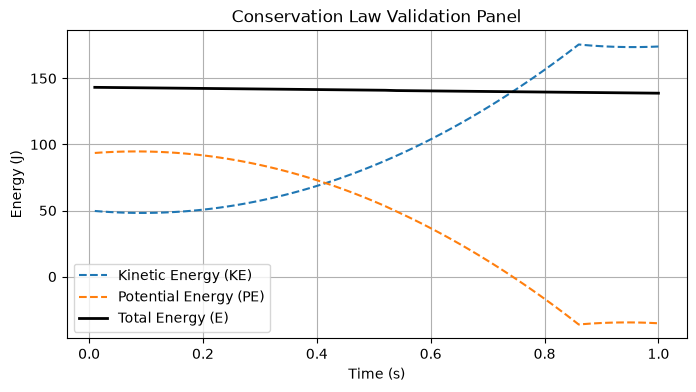

In [4]:
time_hist = world.history["time"]
total_ke = np.zeros(len(time_hist))
total_pe = np.zeros(len(time_hist))

for i in range(len(time_hist)):
    ke_step = 0.0
    pe_step = 0.0
    for body in world.bodies:
        # Pull tracking arrays
        pos = world.history["bodies"][body.name]["pos"][i]
        vel = world.history["bodies"][body.name]["vel"][i]
        
        # KE = 0.5 * m * v^2
        ke_step += 0.5 * body.mass * np.sum(vel**2)
        # PE = m * g * h (y-coordinate)
        pe_step += body.mass * 9.81 * pos[1]
        
    total_ke[i] = ke_step
    total_pe[i] = pe_step

total_energy = total_ke + total_pe

# Plot the Panel
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(time_hist, total_ke, label="Kinetic Energy (KE)", linestyle="--")
ax.plot(time_hist, total_pe, label="Potential Energy (PE)", linestyle="--")
ax.plot(time_hist, total_energy, label="Total Energy (E)", linewidth=2, color="black")
ax.set_title("Conservation Law Validation Panel")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Energy (J)")
ax.legend()
plt.grid(True)
plt.show()
